# Bank Telemarketing Campaign Case Study With Python

#The main aim of the Bank Telemarketing Campaign Analysis project is to analyse customer demographic, financial, and campaign-related data using Python to identify the factors associated with term deposit subscriptions.

# The project aims to:

1.   List item
2.   List item


1. Understand customer behaviour by analysing age, occupation, education, marital status, salary, and account balance.
2. Identify potential customer segments with higher term deposit subscription rates.
3. Evaluate campaign performance by analysing contact methods, call frequency, previous campaign outcomes, and call duration.
4. Perform data cleaning and exploratory data analysis (EDA) using Pandas, NumPy, Matplotlib, and Seaborn.
5. Discover meaningful patterns and trends that may help the bank improve customer targeting.
6. Provide data-driven recommendations to support more effective marketing campaigns and better resource allocation.

In [1]:
# Load the dataset

from google.colab import files
uploaded = files.upload()

Saving bank_telemarketing_20k_synthetic.csv to bank_telemarketing_20k_synthetic.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank_telemarketing_20k_synthetic.csv")
display(df.head())

,customerid,age,job,education,marital,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,salary,response
0,100001,22.0,retired,secondary,married,no,-211,no,no,unknown,12,may,43,4,172,2,failure,40801.0,no
1,100002,37.0,blue-collar,secondary,married,no,-86,no,no,cellular,20,may,56,2,-1,0,unknown,41914.0,no
2,100003,23.0,self-employed,tertiary,married,no,3259,yes,no,telephone,28,jul,99,5,-1,0,unknown,43199.0,yes
3,100004,62.0,services,primary,married,no,237,yes,yes,cellular,12,jan,117,4,-1,0,unknown,61455.0,no
4,100005,43.0,management,secondary,single,no,405,no,no,unknown,27,oct,436,2,256,2,failure,73786.0,no


In [4]:
print("Dataset shape:", df.shape)


Dataset shape: (20000, 19)


In [5]:
#Understand the data

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  20000 non-null  int64  
 1   age         19981 non-null  float64
 2   job         20000 non-null  object 
 3   education   19935 non-null  object 
 4   marital     20000 non-null  object 
 5   default     20000 non-null  object 
 6   balance     20000 non-null  int64  
 7   housing     20000 non-null  object 
 8   loan        20000 non-null  object 
 9   contact     20000 non-null  object 
 10  day         20000 non-null  int64  
 11  month       19951 non-null  object 
 12  duration    20000 non-null  int64  
 13  campaign    20000 non-null  int64  
 14  pdays       20000 non-null  int64  
 15  previous    20000 non-null  int64  
 16  poutcome    20000 non-null  object 
 17  salary      20000 non-null  float64
 18  response    19961 non-null  object 
dtypes: float64(2), int64(7), 

In [ ]:
# Check for duplicate records and customer IDs:

In [8]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [9]:
print("Duplicate customer IDs:", df["customerid"].duplicated().sum())

Duplicate customer IDs: 0


In [10]:
df.columns

Index(['customerid', 'age', 'job', 'education', 'marital', 'default',
       'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration',
       'campaign', 'pdays', 'previous', 'poutcome', 'salary', 'response'],
      dtype='object')

In [11]:
df.describe()

,customerid,age,balance,day,duration,campaign,pdays,previous,salary
count,20000.000000,19981.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.0000,20000.000000
mean,110000.500000,41.147941,573.672200,16.005450,189.647700,3.201400,35.158200,0.4475,55000.320750
std,5773.647028,10.434736,1575.114079,8.904279,133.405371,1.488102,90.995156,1.0872,18592.749855
min,100001.000000,18.000000,-344.000000,1.000000,5.000000,1.000000,-1.000000,0.0000,12000.000000
25%,105000.750000,34.000000,-135.000000,8.000000,91.000000,2.000000,-1.000000,0.0000,41909.250000
50%,110000.500000,41.000000,114.000000,16.000000,159.500000,3.000000,-1.000000,0.0000,55106.000000
75%,115000.250000,48.000000,665.000000,24.000000,256.000000,4.000000,-1.000000,0.0000,67980.000000
max,120000.000000,86.000000,48762.000000,31.000000,1171.000000,11.000000,399.000000,8.0000,128087.000000


In [12]:
# Check data quality

In [13]:
df.isnull().sum()

,0
customerid,0
age,19
job,0
education,65
marital,0
default,0
balance,0
housing,0
loan,0
contact,0


In [14]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
age,19
education,65
month,49
response,39


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df = df.drop_duplicates()

In [17]:
# Fill missing age with median
df['age'] = df['age'].fillna(df['age'].median())

In [18]:
# Fill missing education with mode
df['education'] = df['education'].fillna(df['education'].mode()[0])

In [21]:
# Fill missing month with mode
df['month'] = df['month'].fillna(df['month'].mode()[0])

In [22]:
# Remove rows with missing response
df = df.dropna(subset=['response'])

In [23]:
# Check missing values again
df.isnull().sum()

,0
customerid,0
age,0
job,0
education,0
marital,0
default,0
balance,0
housing,0
loan,0
contact,0


In [24]:
df.shape

(19961, 19)

In [ ]:
#Understand the target variable
#Our target column is response. It tells us whether a customer subscribed to a term deposit.

In [25]:
df['response'].value_counts()

,count
response,
no,15666
yes,4295


In [26]:
# Calculate the percentage of each response:

df['response'].value_counts(normalize=True) * 100

,proportion
response,
no,78.483042
yes,21.516958


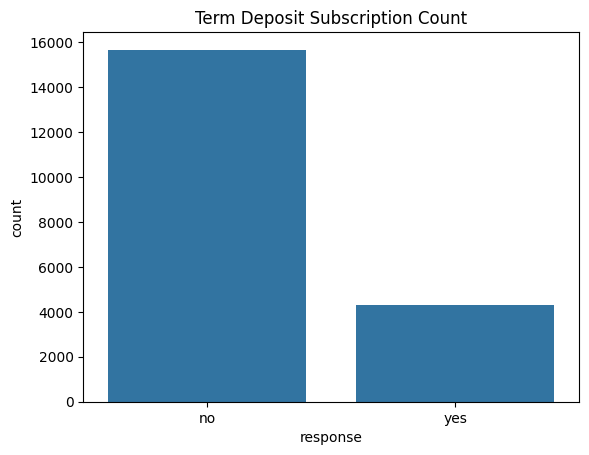

In [27]:
sns.countplot(data=df, x='response')
plt.title('Term Deposit Subscription Count')
plt.show()

In [28]:
# Calculate the overall subscription rate

In [31]:
yes_count = (df['response'] == 'yes').sum()
total_count = len(df)

rate = yes_count / total_count * 100

print("Total customers:", total_count)
print("Subscribed customers:", yes_count)
print("Subscription rate:", round(rate, 2), "%")

Total customers: 19961
Subscribed customers: 4295
Subscription rate: 21.52 %


In [32]:
# Analyse numerical columns

In [33]:
df.select_dtypes(include='number').columns

Index(['customerid', 'age', 'balance', 'day', 'duration', 'campaign', 'pdays',
       'previous', 'salary'],
      dtype='object')

In [34]:
print("Average age:", round(df['age'].mean(), 2))
print("Median age:", df['age'].median())
print("Minimum age:", df['age'].min())
print("Maximum age:", df['age'].max())

Average age: 41.15
Median age: 41.0
Minimum age: 18.0
Maximum age: 86.0


In [35]:
df['balance'].describe()

,balance
count,19961.000000
mean,572.369070
std,1565.269365
min,-344.000000
25%,-135.000000
50%,114.000000
75%,665.000000
max,48762.000000


In [37]:
df['salary'].describe()

,salary
count,19961.000000
mean,55004.603377
std,18587.699303
min,12000.000000
25%,41918.000000
50%,55112.000000
75%,67972.000000
max,128087.000000


In [38]:
df['duration'].describe()

,duration
count,19961.000000
mean,189.640749
std,133.381751
min,5.000000
25%,91.000000
50%,159.000000
75%,256.000000
max,1171.000000


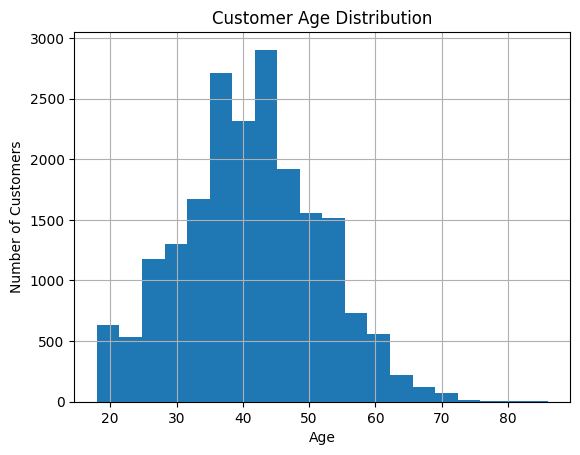

In [39]:
df['age'].hist(bins=20)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

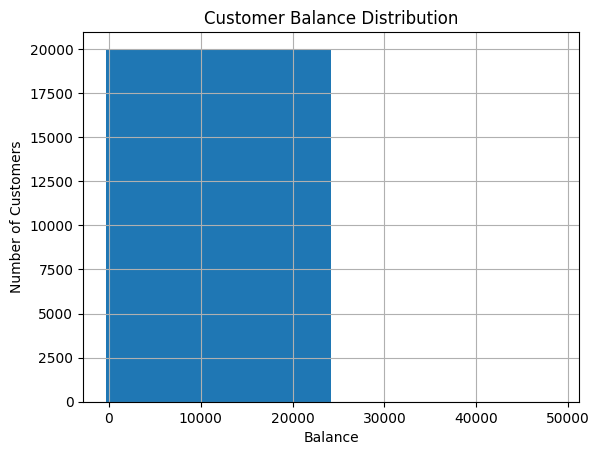

In [45]:
df['balance'].hist(bins=2)
plt.title('Customer Balance Distribution')
plt.xlabel('Balance')
plt.ylabel('Number of Customers')
plt.show()

In [46]:
df['job'].value_counts()

,count
job,
management,4206
technician,3388
blue-collar,3139
admin.,2218
services,1856
retired,1391
self-employed,982
entrepreneur,603
student,600


In [47]:
df['job'].value_counts()

,count
job,
management,4206
technician,3388
blue-collar,3139
admin.,2218
services,1856
retired,1391
self-employed,982
entrepreneur,603
student,600


In [48]:
df['marital'].value_counts()

,count
marital,
married,11911
single,5833
divorced,2217


In [49]:
df['contact'].value_counts()

,count
contact,
cellular,13701
unknown,4659
telephone,1601


In [50]:
df['poutcome'].value_counts()

,count
poutcome,
unknown,16376
failure,2060
success,994
other,531


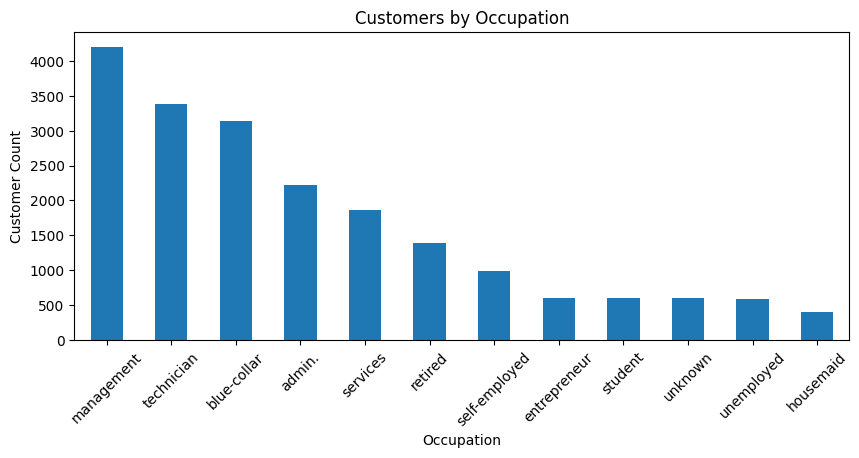

In [51]:
df['job'].value_counts().plot(kind='bar', figsize=(10, 4))
plt.title('Customers by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Customer Count')
plt.xticks(rotation=45)
plt.show()

In [53]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 30, 40, 50, 60, 100],
    labels=['Below 30', '30-40', '40-50', '50-60', '60+'],
    right=False
)

In [54]:
df['age_group'].value_counts().sort_index()

,count
age_group,
Below 30,2735
30-40,6000
40-50,6952
50-60,3431
60+,843


In [55]:
#Analyse subscription rate by age group

In [56]:
age_analysis = df.groupby('age_group', observed=False)['response'].apply(
    lambda x: (x == 'yes').mean() * 100
)

print(age_analysis.round(2))

age_group
Below 30    22.63
30-40       21.08
40-50       21.32
50-60       22.09
60+         20.28
Name: response, dtype: float64


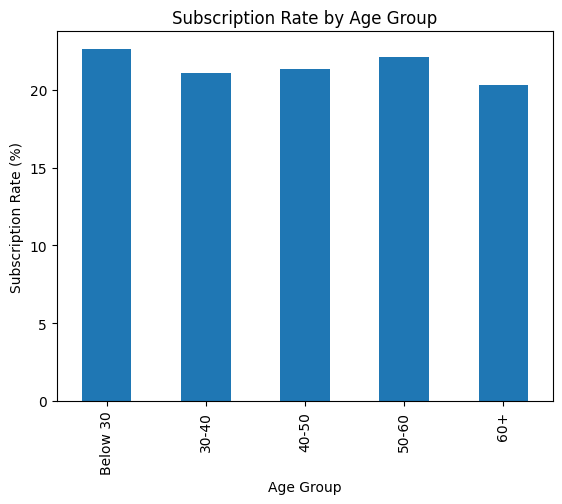

In [57]:
age_analysis.plot(kind='bar')
plt.title('Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')
plt.show()

In [58]:
# Analyse subscription rate by occupation

In [59]:
job_analysis = df.groupby('job')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
).sort_values(ascending=False)

print(job_analysis.round(2))

job
retired          29.98
student          27.50
management       23.35
entrepreneur     22.39
unemployed       20.86
unknown          20.54
services         20.31
admin.           20.29
blue-collar      19.66
technician       19.27
self-employed    18.74
housemaid        17.82
Name: response, dtype: float64


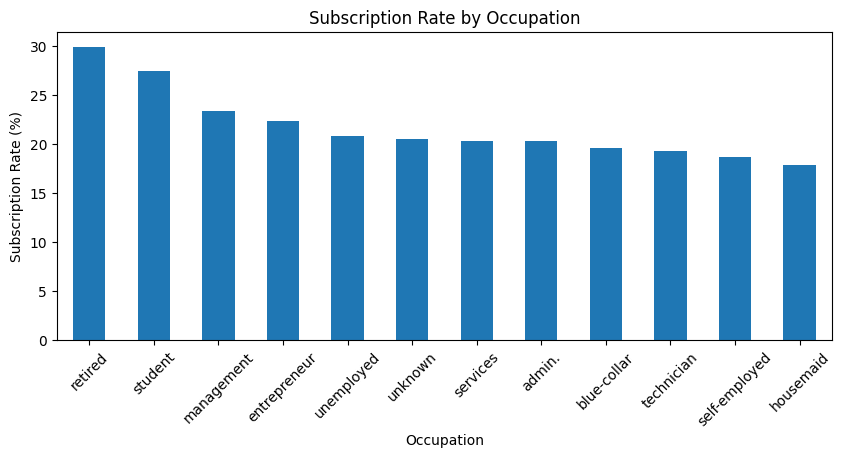

In [60]:
job_analysis.plot(kind='bar', figsize=(10, 4))
plt.title('Subscription Rate by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [61]:
# Analyse education and marital status

In [62]:
education_analysis = df.groupby('education')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
)

print(education_analysis.round(2))

education
primary      21.38
secondary    20.12
tertiary     23.92
unknown      22.06
Name: response, dtype: float64


In [63]:
marital_analysis = df.groupby('marital')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
)

print(marital_analysis.round(2))

marital
divorced    19.85
married     20.54
single      24.16
Name: response, dtype: float64


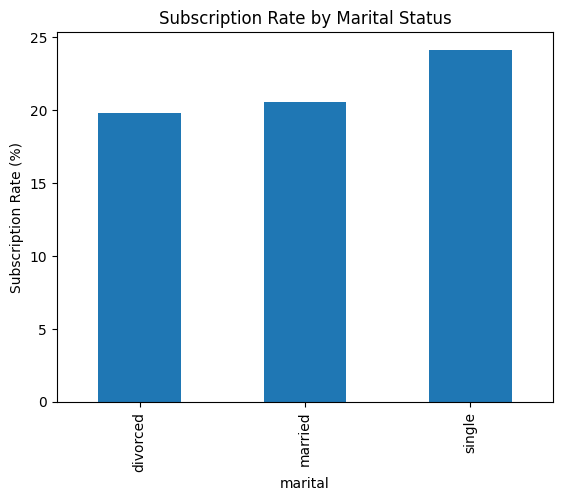

In [64]:
marital_analysis.plot(kind='bar')
plt.title('Subscription Rate by Marital Status')
plt.ylabel('Subscription Rate (%)')
plt.show()

In [65]:
# Analyse loans and credit default

In [66]:
for col in ['housing', 'loan', 'default']:
    result = df.groupby(col)['response'].apply(
        lambda x: (x == 'yes').mean() * 100
    )

    print('\n', col)
    print(result.round(2))


 housing
housing
no     22.79
yes    20.47
Name: response, dtype: float64

 loan
loan
no     21.90
yes    19.51
Name: response, dtype: float64

 default
default
no     21.55
yes    19.51
Name: response, dtype: float64


In [67]:
# Analyse salary and account balance

In [68]:
df.groupby('response')['salary'].mean().round(2)

,salary
response,
no,55051.83
yes,54832.36


In [69]:
df.groupby('response')['salary'].median()

,salary
response,
no,55137.0
yes,55008.0


In [70]:
df.groupby('response')['balance'].mean().round(2)

,balance
response,
no,253.23
yes,1736.42


In [71]:
df.groupby('response')['balance'].median()

,balance
response,
no,38.0
yes,805.0


In [72]:
contact_analysis = df.groupby('contact')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
)

print(contact_analysis.round(2))

contact
cellular     21.53
telephone    20.67
unknown      21.76
Name: response, dtype: float64


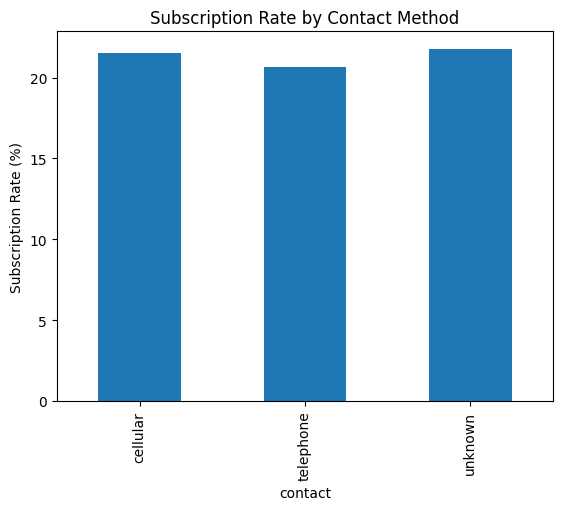

In [73]:
contact_analysis.plot(kind='bar')
plt.title('Subscription Rate by Contact Method')
plt.ylabel('Subscription Rate (%)')
plt.show()

In [75]:
df.groupby('campaign')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
).head(15).round(2)

,response
campaign,
1,21.61
2,21.47
3,22.32
4,20.99
5,21.35
6,20.06
7,21.75
8,18.55
9,13.33


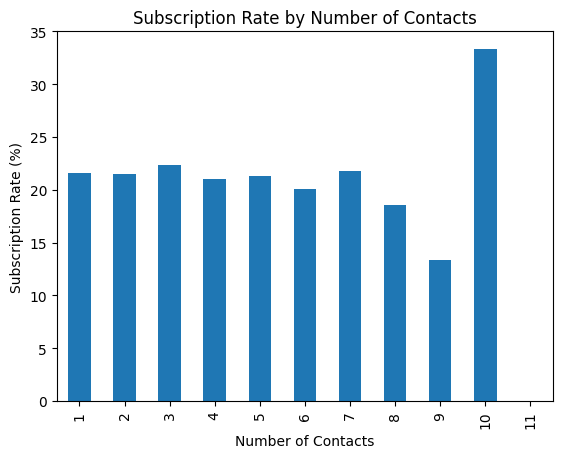

In [76]:
campaign_rate = df.groupby('campaign')['response'].apply(
    lambda x: (x == 'yes').mean() * 100
)

campaign_rate.head(15).plot(kind='bar')
plt.title('Subscription Rate by Number of Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Subscription Rate (%)')
plt.show()

In [74]:
total_customers = len(df)
subscribers = (df['response'] == 'yes').sum()

print("PROJECT SUMMARY")
print("--------------------------")
print("Total Customers:", total_customers)
print("Total Subscribers:", subscribers)
print("Total Non-Subscribers:", total_customers - subscribers)
print("Subscription Rate:", round(subscribers / total_customers * 100, 2), "%")
print("Non-Subscription Rate:", round((total_customers - subscribers) / total_customers * 100, 2), "%")

PROJECT SUMMARY
--------------------------
Total Customers: 19961
Total Subscribers: 4295
Total Non-Subscribers: 15666
Subscription Rate: 21.52 %
Non-Subscription Rate: 78.48 %
